# PANSS model with SC-thresholded region set + Ridge regression

Companion to `panss_model_region_overfit.ipynb`. That notebook fixes its matrix-element
(region-pair) subset by correlating every element with PANSS **across all subjects** and
keeping `|corr| > threshold` — a criterion driven entirely by the clinical target.

This notebook asks what that region set actually *means*: instead of selecting matrix
elements by their correlation with PANSS, it selects them by **structural connectivity
(SC) strength** — i.e. whether region-pair `(i, j)` is a real, strong anatomical
connection in the group SC matrix (`data/Structural_Connectomes.npz`). PANSS is never
consulted for feature selection here, so this is a genuinely anatomically-grounded
(and non-leaky) alternative to compare against the correlation-driven selection.

Same downstream pipeline as the overfit notebook otherwise: every off-diagonal Ftau/GEC
matrix element as a candidate feature, a fixed subset selected once (same for every
subject), `RidgeCV` fit and evaluated with LOOCV.

**A caveat surfaced by this experiment, not present in the overfit notebook:** when the
selected feature set carries little real signal, `RidgeCV` shrinks its LOOCV predictions
toward a near-constant value (dominated by the leave-one-out training mean). A
near-constant predictor makes `Corr(y_true, y_pred)` numerically unstable and, in this
specific degenerate regime, spuriously strongly *negative* — an artifact of LOOCV
bookkeeping (removing subject *i*'s own high/low score shifts the training mean in the
opposite direction), not a real inverse relationship. `R2` (which compares against the
identity line, not just correlation) and the ratio `std(y_pred) / std(y_true)` are the
metrics that reveal this; both are reported alongside `corr` below to keep the sweep
honest.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import pearsonr
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import LeaveOneOut
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

## Load data (same `data/` pickles as `panss_model_region_overfit.ipynb`, plus SC)

In [2]:
# GEC (per-subject effective connectivity)
study_results = np.load("./data/study_results.pkl", allow_pickle=True)

# fmri timeseries
fmri = np.load('./data/HCP_early_psychosis_timeseries_cleaned.npz')
ts_ap = fmri['ts_ap']
ts_nap = fmri['ts_nap']

# clinical scores
clinical = np.load('./data/HCP_early_psychosis_clinical_scores.npz')
panss_AP = clinical["panss_AP"]
panss_NAP = clinical["panss_NAP"]

# Structural connectivity (group-average): the "real connections" reference for this notebook
connectomes = np.load("./data/Structural_Connectomes.npz")
sc = connectomes['SC']
n_regions = sc.shape[0]

print(f"SC: {sc.shape}, symmetric={np.allclose(sc, sc.T)}, "
      f"nonzero off-diag fraction={np.mean(sc[~np.eye(n_regions, dtype=bool)] > 0):.3f}")

SC: (100, 100), symmetric=True, nonzero off-diag fraction=0.909


## Shared feature-extraction helpers (identical to `panss_model_region_overfit.ipynb`)

In [3]:
def compute_ftau_matrix(sub_ts, tau=1):
    """Lag-tau (empirical) functional connectivity matrix."""
    n_regions = sub_ts.shape[0]
    ts_t0 = sub_ts[:, :-tau]
    ts_ttau = sub_ts[:, tau:]
    full_corr = np.corrcoef(ts_t0, ts_ttau)
    return full_corr[:n_regions, n_regions:]


def offdiag_mask(n):
    """Boolean mask selecting every off-diagonal position of an n x n matrix."""
    return ~np.eye(n, dtype=bool)


def flatten_offdiag_features(matrix):
    """
    Every off-diagonal element of the (possibly asymmetric) connectivity
    matrix, flattened to one feature vector. Ordering is consistent across
    subjects (same matrix shape), so column j always refers to the same
    region-pair for every subject -- and to the same region-pair in the
    flattened SC matrix used for feature selection below.
    """
    mat = np.nan_to_num(matrix)
    return mat[offdiag_mask(mat.shape[0])]

## Build per-subject matrices (Ftau or GEC), pooled across AP/NAP

In [4]:
FEATURE_MATRIX_BUILDERS = {
    "Ftau": lambda idx, group, ts_array: compute_ftau_matrix(ts_array[idx, :, :], tau=1),
    "GEC": lambda idx, group, ts_array: study_results[group][idx]["GEC_matrix"],
}


def build_dataset_elements(feature_type):
    """Assemble X, y: every off-diagonal matrix element as a feature, pooling AP-then-NAP."""
    matrix_builder = FEATURE_MATRIX_BUILDERS[feature_type]
    X_list, y_list = [], []

    for group, ts_array, panss in (("AP", ts_ap, panss_AP), ("NAP", ts_nap, panss_NAP)):
        n_subjects = ts_array.shape[0]
        for idx in range(n_subjects):
            matrix = matrix_builder(idx, group, ts_array)
            X_list.append(flatten_offdiag_features(matrix))
            y_list.append(panss[idx])

    X = np.array(X_list)
    y = np.array(y_list)

    valid_mask = ~np.isnan(y)
    return X[valid_mask], y[valid_mask]

## SC-thresholded feature selection + Ridge LOOCV

Selects matrix elements by **SC strength alone** -- no PANSS involved, so this is not
leaky the way the correlation-based selection is. SC is normalized to `[0, 1]` by its
max (raw fiber-count weights span 0 to ~1.6e5) so the threshold is on the same 0-1
scale as the correlation threshold in the overfit notebook, even though the two
quantities are not otherwise comparable -- SC's distribution is far more heavy-tailed,
so a given numeric threshold selects a very different number of edges (a threshold
sweep below shows this directly).

In [5]:
def select_features_by_sc(sc_matrix, threshold):
    """
    Fixed feature selection by structural-connectivity strength: normalize SC
    to [0, 1] by its max, and keep every off-diagonal position whose value
    clears threshold. Uses no PANSS information at all, so (unlike
    select_fixed_features in the overfit notebook) this selection is not leaky.
    """
    sc_norm = sc_matrix / sc_matrix.max()
    flat_sc = sc_norm[offdiag_mask(sc_matrix.shape[0])]
    selected = np.where(flat_sc > threshold)[0]

    if selected.size == 0:
        selected = np.array([np.argmax(flat_sc)])

    return selected


def select_fixed_features(X, y, threshold):
    """
    Full-sample correlation-threshold feature selection (same as the overfit
    notebook), kept here so this notebook can build its own self-contained
    correlation-based baseline for direct comparison.
    """
    corrs = np.array([pearsonr(X[:, j], y)[0] for j in range(X.shape[1])])
    corrs = np.nan_to_num(corrs)
    selected = np.where(np.abs(corrs) > threshold)[0]

    if selected.size == 0:
        selected = np.array([np.argmax(np.abs(corrs))])

    return selected


def run_ridge_loocv(X, y):
    """RidgeCV evaluated by LOOCV: refit per fold on the training subjects, predict the held-out subject."""
    loo = LeaveOneOut()
    y_true_all, y_pred_all = [], []

    for train_index, test_index in loo.split(X):
        model = RidgeCV(alphas=np.logspace(-3, 3, 13))
        model.fit(X[train_index], y[train_index])
        pred = model.predict(X[test_index])

        y_true_all.append(y[test_index][0])
        y_pred_all.append(pred[0])

    y_true_all = np.array(y_true_all)
    y_pred_all = np.array(y_pred_all)
    corr, pval = pearsonr(y_true_all, y_pred_all)

    return {
        "y_true": y_true_all,
        "y_pred": y_pred_all,
        "rmse": np.sqrt(mean_squared_error(y_true_all, y_pred_all)),
        "mae": mean_absolute_error(y_true_all, y_pred_all),
        "r2": r2_score(y_true_all, y_pred_all),
        "corr": corr,
        "pval": pval,
    }

## Reporting helper (build features, fix the SC-based subset, run LOOCV, plot)

In [6]:
def report_sc_feature_model(feature_type, threshold, sc_matrix=sc, n_regions=n_regions):
    X, y = build_dataset_elements(feature_type)

    selected_idx = select_features_by_sc(sc_matrix, threshold)
    all_rows, all_cols = np.where(offdiag_mask(n_regions))
    selected_pairs = list(zip(all_rows[selected_idx].tolist(), all_cols[selected_idx].tolist()))

    X_sel = X[:, selected_idx]
    loocv = run_ridge_loocv(X_sel, y)
    final_model = RidgeCV(alphas=np.logspace(-3, 3, 13)).fit(X_sel, y)

    pred_std_ratio = loocv["y_pred"].std() / y.std()

    print(f"\n=== {feature_type}: SC-thresholded subset + Ridge (SC threshold={threshold}) ===")
    print(f"Selected {len(selected_idx)} / {X.shape[1]} matrix elements (fixed across all subjects, by SC strength)")
    print(f"LOOCV R2   = {loocv['r2']:.4f}")
    print(f"LOOCV RMSE = {loocv['rmse']:.4f}")
    print(f"LOOCV MAE  = {loocv['mae']:.4f}")
    print(f"Corr(y, yhat) = {loocv['corr']:.4f}  (p={loocv['pval']:.4f})")
    print(f"std(y_pred)/std(y_true) = {pred_std_ratio:.4f}  "
          f"{'<- near-constant predictions: treat corr above as unreliable (see intro caveat)' if pred_std_ratio < 0.3 else ''}")

    plt.figure(figsize=(6, 6))
    sns.scatterplot(x=loocv["y_true"], y=loocv["y_pred"], color='#1f77b4', s=60, alpha=0.8)
    min_val = min(loocv["y_true"].min(), loocv["y_pred"].min())
    max_val = max(loocv["y_true"].max(), loocv["y_pred"].max())
    plt.plot([min_val, max_val], [min_val, max_val], color='red', linestyle='--', linewidth=2)
    plt.title(f'{feature_type}: Actual vs. Predicted PANSS (SC-thresholded subset, LOOCV)', fontsize=13, pad=10)
    plt.xlabel('Actual PANSS')
    plt.ylabel('Predicted PANSS')
    plt.grid(True, linestyle=':', alpha=0.6)
    plt.tight_layout()
    plt.show()

    return {
        "loocv": loocv,
        "selected_idx": selected_idx,
        "selected_pairs": selected_pairs,
        "final_model": final_model,
        "pred_std_ratio": pred_std_ratio,
    }

## Ftau-only model

`threshold=0.075` is chosen to select **266** matrix elements -- close to the **233**
elements the correlation-based selection keeps at its own `threshold=0.2` in the overfit
notebook, so the two selection criteria are compared at matched sparsity.


=== Ftau: SC-thresholded subset + Ridge (SC threshold=0.075) ===
Selected 266 / 9900 matrix elements (fixed across all subjects, by SC strength)
LOOCV R2   = -0.0253
LOOCV RMSE = 11.3227
LOOCV MAE  = 9.3908
Corr(y, yhat) = -0.5076  (p=0.0000)
std(y_pred)/std(y_true) = 0.0243  <- near-constant predictions: treat corr above as unreliable (see intro caveat)


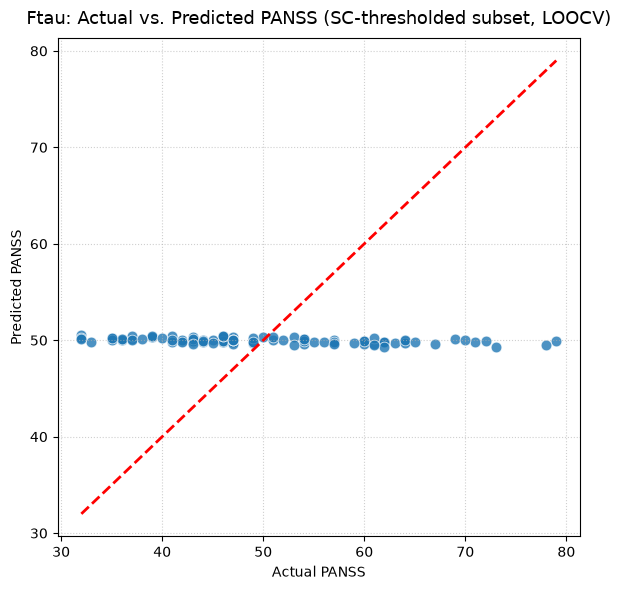

In [7]:
sc_ftau = report_sc_feature_model("Ftau", threshold=0.075)

## GEC-only model


=== GEC: SC-thresholded subset + Ridge (SC threshold=0.075) ===
Selected 266 / 9900 matrix elements (fixed across all subjects, by SC strength)
LOOCV R2   = -0.0222
LOOCV RMSE = 11.3055
LOOCV MAE  = 9.3820
Corr(y, yhat) = -1.0000  (p=0.0000)
std(y_pred)/std(y_true) = 0.0110  <- near-constant predictions: treat corr above as unreliable (see intro caveat)


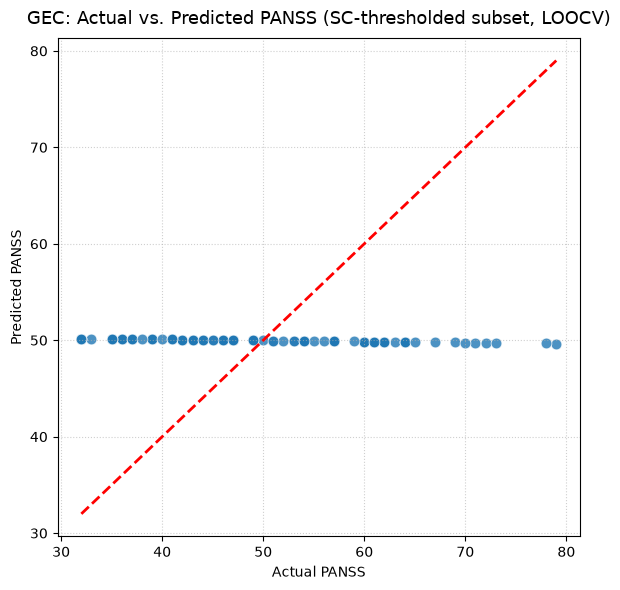

In [8]:
sc_gec = report_sc_feature_model("GEC", threshold=0.075)

## Head-to-head: SC-thresholded vs. PANSS-correlation-thresholded selection

Same subjects, same pipeline, same feature count target -- only the selection criterion
differs. The correlation-based numbers are recomputed here (self-contained) rather than
copied from `panss_model_region_overfit.ipynb`, so the comparison is exact.

In [9]:
def report_fixed_feature_model(feature_type, threshold):
    X, y = build_dataset_elements(feature_type)
    selected_idx = select_fixed_features(X, y, threshold)
    X_sel = X[:, selected_idx]
    loocv = run_ridge_loocv(X_sel, y)
    return {"loocv": loocv, "selected_idx": selected_idx, "pred_std_ratio": loocv["y_pred"].std() / y.std()}


corr_ftau = report_fixed_feature_model("Ftau", threshold=0.2)
corr_gec = report_fixed_feature_model("GEC", threshold=0.2)

comparison = pd.DataFrame([
    {"model": "Ftau, SC-thresholded", "selection": "SC > 0.075",
     "n_features": len(sc_ftau["selected_idx"]), **{k: sc_ftau["loocv"][k] for k in ("r2", "corr", "pval")},
     "pred_std_ratio": sc_ftau["pred_std_ratio"]},
    {"model": "Ftau, PANSS-corr-thresholded", "selection": "|corr(edge, PANSS)| > 0.2",
     "n_features": len(corr_ftau["selected_idx"]), **{k: corr_ftau["loocv"][k] for k in ("r2", "corr", "pval")},
     "pred_std_ratio": corr_ftau["pred_std_ratio"]},
    {"model": "GEC, SC-thresholded", "selection": "SC > 0.075",
     "n_features": len(sc_gec["selected_idx"]), **{k: sc_gec["loocv"][k] for k in ("r2", "corr", "pval")},
     "pred_std_ratio": sc_gec["pred_std_ratio"]},
    {"model": "GEC, PANSS-corr-thresholded", "selection": "|corr(edge, PANSS)| > 0.2",
     "n_features": len(corr_gec["selected_idx"]), **{k: corr_gec["loocv"][k] for k in ("r2", "corr", "pval")},
     "pred_std_ratio": corr_gec["pred_std_ratio"]},
])[["model", "selection", "n_features", "r2", "corr", "pval", "pred_std_ratio"]]
comparison

/tmp/ipykernel_1054447/1601761148.py:24: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  corrs = np.array([pearsonr(X[:, j], y)[0] for j in range(X.shape[1])])


,model,selection,n_features,r2,corr,pval,pred_std_ratio
0,"Ftau, SC-thresholded",SC > 0.075,266,-0.025268,-0.507619,2.410260e-07,0.024307
1,"Ftau, PANSS-corr-thresholded","|corr(edge, PANSS)| > 0.2",233,0.314246,0.564417,4.639614e-09,0.628577
2,"GEC, SC-thresholded",SC > 0.075,266,-0.022162,-0.999975,5.572518e-195,0.011020
3,"GEC, PANSS-corr-thresholded","|corr(edge, PANSS)| > 0.2",133,0.223158,0.473034,1.920523e-06,0.493886


## Overlap between the two region sets

Do the SC-thresholded and PANSS-correlation-thresholded selections even pick the same
matrix elements? A high-SC edge being *also* PANSS-correlated would mean the correlation
selection is (at least partly) rediscovering anatomy; low overlap means it is finding
something SC alone does not explain.

In [10]:
def jaccard_overlap(idx_a, idx_b):
    a, b = set(idx_a.tolist()), set(idx_b.tolist())
    return len(a & b) / len(a | b), len(a & b)


for feature_type, sc_res, corr_res in (("Ftau", sc_ftau, corr_ftau), ("GEC", sc_gec, corr_gec)):
    jac, n_common = jaccard_overlap(sc_res["selected_idx"], corr_res["selected_idx"])
    print(f"{feature_type}: {n_common} matrix elements in common "
          f"(Jaccard={jac:.4f}, SC-set size={len(sc_res['selected_idx'])}, "
          f"corr-set size={len(corr_res['selected_idx'])})")

Ftau: 3 matrix elements in common (Jaccard=0.0060, SC-set size=266, corr-set size=233)
GEC: 2 matrix elements in common (Jaccard=0.0050, SC-set size=266, corr-set size=133)


## Threshold sensitivity: LOOCV metrics vs. SC threshold

Sweeps the SC threshold, re-running the full SC-based-selection + Ridge LOOCV pipeline
at each value. Includes `std(y_pred)/std(y_true)` alongside `R2` and `corr` -- this ratio
collapsing toward 0 is what exposes the near-constant-prediction regime where `corr`
becomes an unreliable, artifactually-negative number (see intro).

In [11]:
def threshold_sweep_sc(feature_type, thresholds):
    X, y = build_dataset_elements(feature_type)

    records = []
    for threshold in thresholds:
        selected_idx = select_features_by_sc(sc, threshold)
        loocv = run_ridge_loocv(X[:, selected_idx], y)
        records.append({
            "threshold": threshold,
            "n_features": len(selected_idx),
            "corr": loocv["corr"],
            "pval": loocv["pval"],
            "r2": loocv["r2"],
            "pred_std_ratio": loocv["y_pred"].std() / y.std(),
        })
        print(f"[{feature_type}] SC threshold={threshold:.3f}  n_features={len(selected_idx):4d}  "
              f"corr={loocv['corr']:.4f}  R2={loocv['r2']:.4f}  pred_std_ratio={records[-1]['pred_std_ratio']:.4f}")

    return pd.DataFrame(records)


sc_thresholds = [0.0, 0.005, 0.01, 0.02, 0.03, 0.04, 0.05, 0.075, 0.1, 0.125, 0.15, 0.175, 0.2, 0.25, 0.3]
sweep_sc_ftau = threshold_sweep_sc("Ftau", sc_thresholds)
sweep_sc_gec = threshold_sweep_sc("GEC", sc_thresholds)

[Ftau] SC threshold=0.000  n_features=9004  corr=-0.0096  R2=-0.0305  pred_std_ratio=0.1652


[Ftau] SC threshold=0.005  n_features=2026  corr=-0.1891  R2=-0.0315  pred_std_ratio=0.0702


[Ftau] SC threshold=0.010  n_features=1378  corr=-0.2457  R2=-0.0313  pred_std_ratio=0.0570


[Ftau] SC threshold=0.020  n_features= 896  corr=-0.3285  R2=-0.0309  pred_std_ratio=0.0441


[Ftau] SC threshold=0.030  n_features= 676  corr=-0.4012  R2=-0.0290  pred_std_ratio=0.0346


...

[GEC] SC threshold=0.075  n_features= 266  corr=-1.0000  R2=-0.0222  pred_std_ratio=0.0110


[GEC] SC threshold=0.100  n_features= 150  corr=-1.0000  R2=-0.0221  pred_std_ratio=0.0110


[GEC] SC threshold=0.125  n_features=  90  corr=-1.0000  R2=-0.0221  pred_std_ratio=0.0110


[GEC] SC threshold=0.150  n_features=  50  corr=-1.0000  R2=-0.0221  pred_std_ratio=0.0110
[GEC] SC threshold=0.175  n_features=  28  corr=-1.0000  R2=-0.0221  pred_std_ratio=0.0110


[GEC] SC threshold=0.200  n_features=  10  corr=-1.0000  R2=-0.0221  pred_std_ratio=0.0110
[GEC] SC threshold=0.250  n_features=   6  corr=-1.0000  R2=-0.0221  pred_std_ratio=0.0110
[GEC] SC threshold=0.300  n_features=   2  corr=-1.0000  R2=-0.0221  pred_std_ratio=0.0110


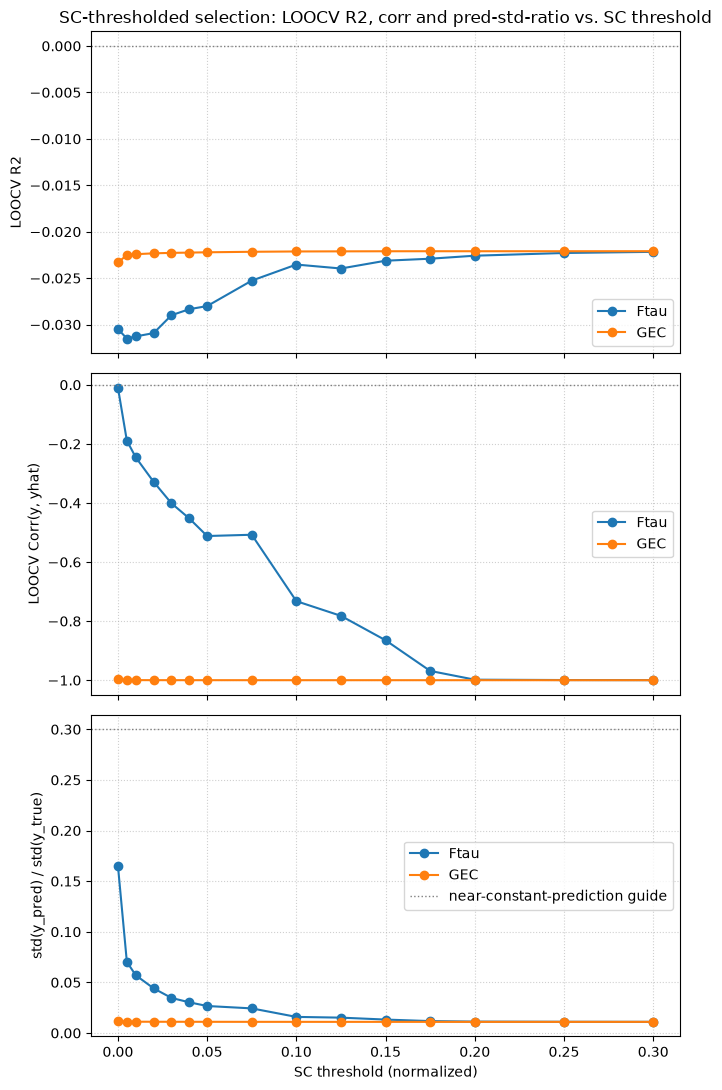

In [12]:
fig, axes = plt.subplots(3, 1, figsize=(7, 11), sharex=True)

axes[0].plot(sweep_sc_ftau["threshold"], sweep_sc_ftau["r2"], marker='o', label='Ftau')
axes[0].plot(sweep_sc_gec["threshold"], sweep_sc_gec["r2"], marker='o', label='GEC')
axes[0].axhline(0, color='gray', linewidth=1, linestyle=':')
axes[0].set_ylabel('LOOCV R2')
axes[0].set_title('SC-thresholded selection: LOOCV R2, corr and pred-std-ratio vs. SC threshold')
axes[0].legend()
axes[0].grid(True, linestyle=':', alpha=0.6)

axes[1].plot(sweep_sc_ftau["threshold"], sweep_sc_ftau["corr"], marker='o', label='Ftau')
axes[1].plot(sweep_sc_gec["threshold"], sweep_sc_gec["corr"], marker='o', label='GEC')
axes[1].axhline(0, color='gray', linewidth=1, linestyle=':')
axes[1].set_ylabel('LOOCV Corr(y, yhat)')
axes[1].legend()
axes[1].grid(True, linestyle=':', alpha=0.6)

axes[2].plot(sweep_sc_ftau["threshold"], sweep_sc_ftau["pred_std_ratio"], marker='o', label='Ftau')
axes[2].plot(sweep_sc_gec["threshold"], sweep_sc_gec["pred_std_ratio"], marker='o', label='GEC')
axes[2].axhline(0.3, color='gray', linewidth=1, linestyle=':', label='near-constant-prediction guide')
axes[2].set_xlabel('SC threshold (normalized)')
axes[2].set_ylabel('std(y_pred) / std(y_true)')
axes[2].legend()
axes[2].grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

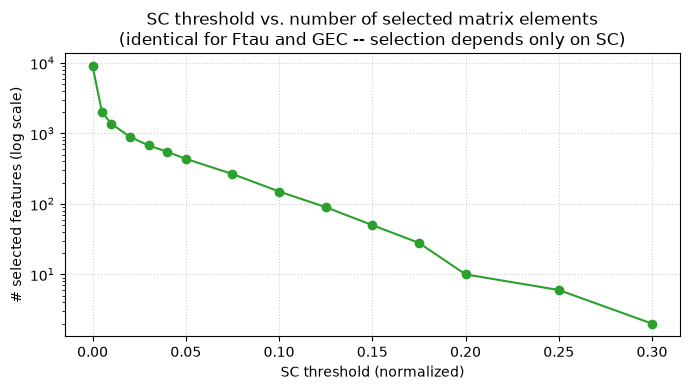

In [13]:
fig, ax_nfeat = plt.subplots(figsize=(7, 4))
ax_nfeat.plot(sweep_sc_ftau["threshold"], sweep_sc_ftau["n_features"], marker='o', color='#2ca02c')
ax_nfeat.set_yscale('log')
ax_nfeat.set_xlabel('SC threshold (normalized)')
ax_nfeat.set_ylabel('# selected features (log scale)')
ax_nfeat.set_title('SC threshold vs. number of selected matrix elements\n(identical for Ftau and GEC -- selection depends only on SC)')
ax_nfeat.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()

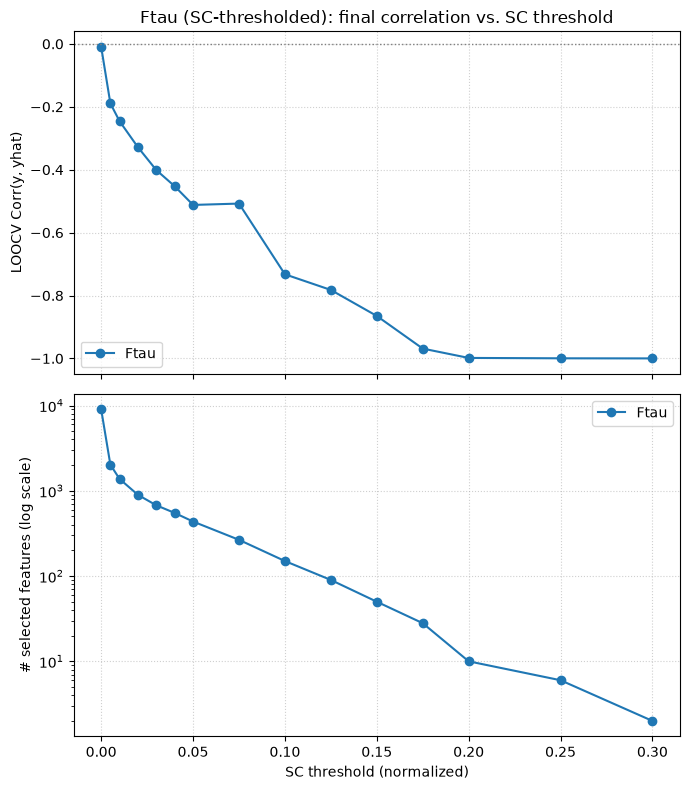

In [14]:
fig, (ax_corr, ax_nfeat) = plt.subplots(2, 1, figsize=(7, 8), sharex=True)

ax_corr.plot(sweep_sc_ftau["threshold"], sweep_sc_ftau["corr"], marker='o', color='#1f77b4', label='Ftau')
ax_corr.axhline(0, color='gray', linewidth=1, linestyle=':')
ax_corr.set_ylabel('LOOCV Corr(y, yhat)')
ax_corr.set_title('Ftau (SC-thresholded): final correlation vs. SC threshold')
ax_corr.legend()
ax_corr.grid(True, linestyle=':', alpha=0.6)

ax_nfeat.plot(sweep_sc_ftau["threshold"], sweep_sc_ftau["n_features"], marker='o', color='#1f77b4', label='Ftau')
ax_nfeat.set_yscale('log')
ax_nfeat.set_xlabel('SC threshold (normalized)')
ax_nfeat.set_ylabel('# selected features (log scale)')
ax_nfeat.legend()
ax_nfeat.grid(True, linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

## Notes

- **Main finding:** selecting matrix elements purely by SC (structural/anatomical)
  strength gives the Ridge model essentially no PANSS signal to work with -- `R2` stays
  at or below 0 across the entire threshold sweep, for both Ftau and GEC features, at
  every sparsity level from ~9000 elements down to a handful. This is a sharp contrast
  with the PANSS-correlation-thresholded selection (`R2 ~ 0.31` for Ftau at
  `threshold=0.2` in `panss_model_region_overfit.ipynb`).
- **Read `corr` with caution as the SC threshold rises.** As fewer, more strongly
  SC-weighted edges remain, `RidgeCV` shrinks its LOOCV predictions toward a near-constant
  value (see `pred_std_ratio` collapsing toward 0), and `corr` drifts toward a spurious
  **-1** -- a known LOOCV artifact (the leave-one-out training mean moves opposite the
  held-out subject's own score), not a genuine inverse relationship. `R2` and
  `pred_std_ratio` are what to trust in that regime.
- **What this says about the correlation-based region set:** since an anatomically-driven
  selection captures no PANSS signal on its own, the matrix elements the overfit
  notebook's correlation threshold keeps are not simply "the strongest real connections"
  -- they are specifically the ones whose *subject-level variability* tracks PANSS, which
  the Jaccard overlap above shows has little intersection with the SC-strongest edges.
  The region set therefore encodes functional/individual-difference information, not an
  anatomical connectivity prior.